Tehtävä 11
Mittaa vähintään minuutin mittainen tasavauhtinen kävely käyttäen painovoimasta puhdistettua kiihtyvyysmittausta. Pidä mittauslaite samassa asennossa ja samassa paikassa koko mittauksen ajan. Laske askeleet myös itse.

a) Piirrä kiihtyvyyden komponentit ja valitse analyysiin sopivin.

b) Kokeile eri suodatusrajoja. Pyri poistamaan selvästi askeltaajuutta pienemmät ja suuremmat taajuudet ja tarkastele valintojen vaikutusta signaaliin.

c) Laske askelmäärä suodatetusta signaalista esimerkiksi huippujen tai nollan ylitysten avulla.

d) Vertaa tulosta itse laskemaasi askelmäärään.

e) Perustele valitsemasi komponentti ja suodatus. Säilytä aineisto tehtävää 15 varten.

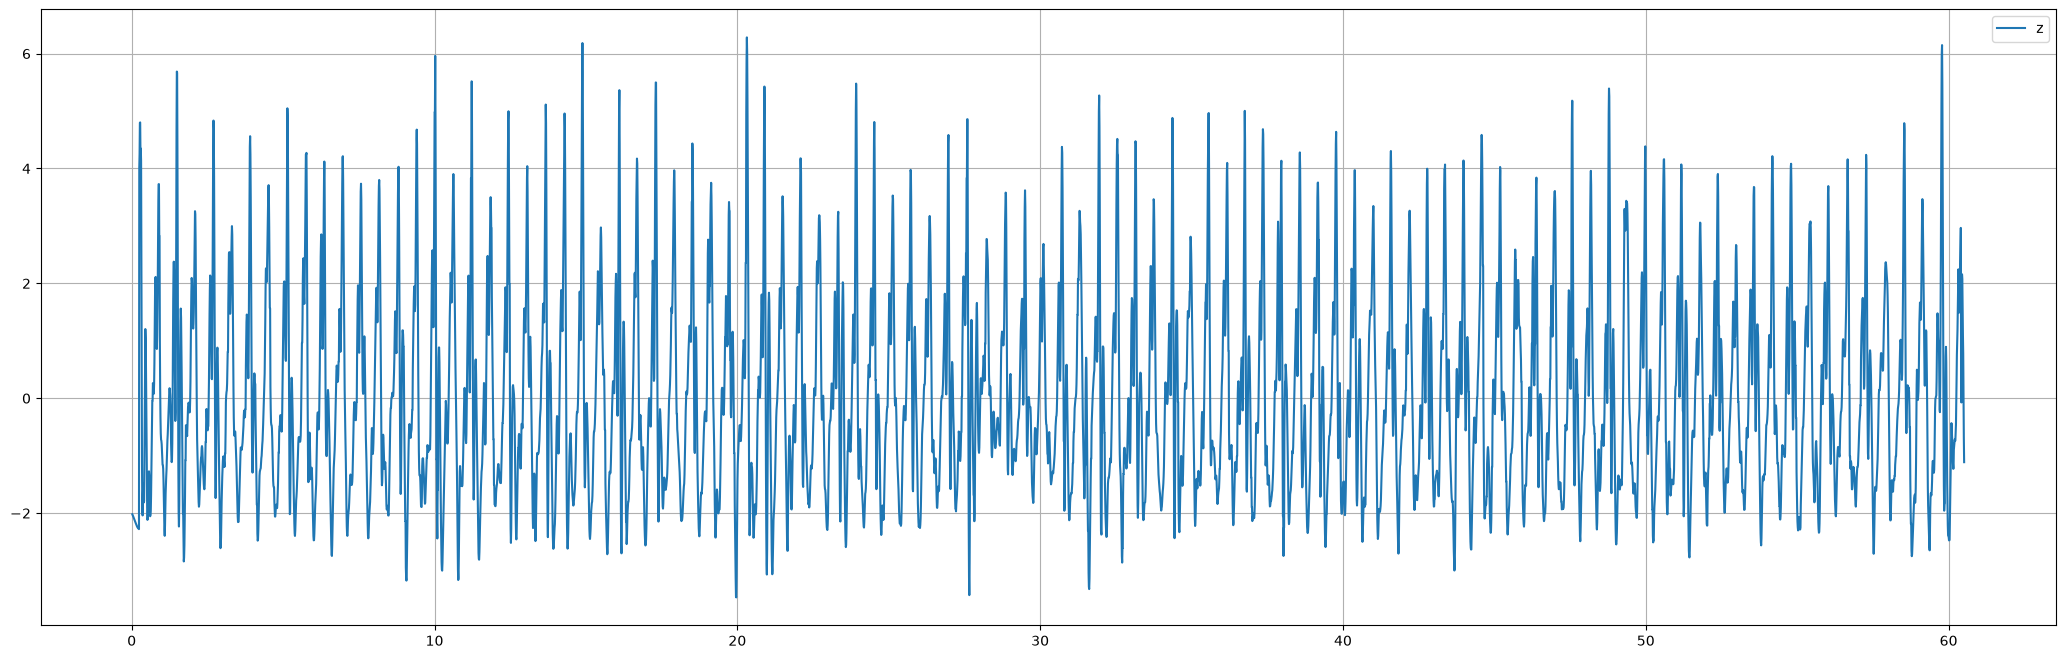

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#Time (s)	Linear Acceleration x (m/s^2)	Linear Acceleration y (m/s^2)	Linear Acceleration z (m/s^2)	Absolute acceleration (m/s^2)
df = pd.read_csv('./Data/Acceleration_withoutG/walkingData.csv')
plt.figure(figsize=(26,8))
#plt.plot(df['Time (s)'],df['Linear Acceleration x (m/s^2)'], label= 'x')
#plt.plot(df['Time (s)'],df['Linear Acceleration y (m/s^2)'], label= 'y')
plt.plot(df['Time (s)'],df['Linear Acceleration z (m/s^2)'], label= 'z')
plt.legend()
plt.grid()

In [16]:
from scipy.signal import butter, filtfilt, sosfiltfilt

def butter_lowpass_filter(data, cutoff, fs, nyq, order):
    normal_cutoff = cutoff / nyq
    # Get the filter coefficients
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = filtfilt(b, a, data)
    return y
     
def butter_highpass_filter(data, cutoff, fs, nyq, order):
    normal_cutoff = cutoff / nyq 
    # Get the filter coefficients
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    y = filtfilt(b, a, data)
    return y

askelmäärät nollan ylityksistä laskettuna on:  99.5
huippujen määrästä laskettuna on:  99.5


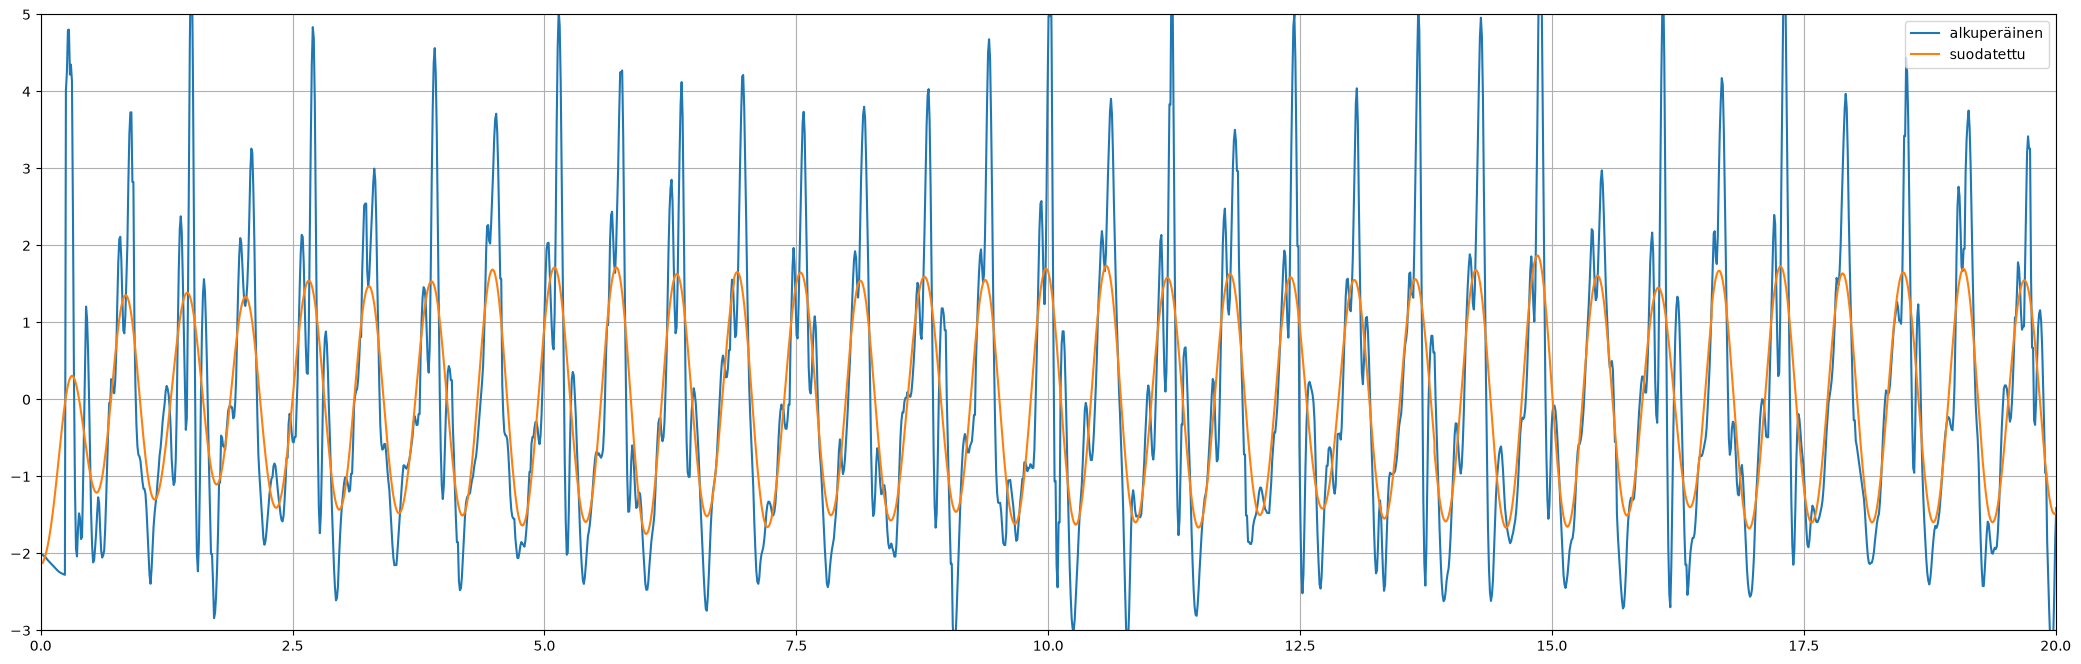

In [ ]:
#valitaan z komponentti
#filttereiden parametrit
T= np.max(df['Time (s)'] - np.min(df['Time (s)'])) #koko datan pituus
n = len(df['Time (s)'] ) #Datapisteiden lukumäärä eli 3000
fs = n/T #datapisteiden lukumäärä 100
nyq = fs/2 #nyqvistin taajuus
order = 3 #kertaluku
cutoff = 1/0.5 #Cutt-off taajuus

df['acc_filt'] = butter_lowpass_filter(df['Linear Acceleration z (m/s^2)'], cutoff, fs, nyq, order)

plt.figure(figsize=(26,8))
plt.plot(df['Time (s)'], df['Linear Acceleration z (m/s^2)'], label='alkuperäinen')
plt.plot(df['Time (s)'], df['acc_filt'], label='suodatettu')
plt.legend()
plt.axis([0,20,-3,5])
plt.grid()
plt.show


#nollan ylitys: Signaalin etumerkki vaihtuu
#huippu: Derivaatan arvo muuttuu, eli peräkkäisten arvojen erotus vaihtaa etumerkkiä

df['acc_diff'] = df['acc_filt'].diff() #peräkkäisten arvojen erotus


nollanYlitykset = 0
huiput = 0
for i in range(n-1): 
    if df['acc_diff'].iloc[i]/df['acc_diff'].iloc[i+1] < 0:
        huiput = huiput + 1
    if df['acc_filt'].iloc[i]/df['acc_filt'].iloc[i+1] < 0:
        nollanYlitykset = nollanYlitykset +1

#jokaiseen askeleeseen liittyy kaksi huippua positiivinen ja negatiivinen
#ja kaksi nollan ylitystä 
print("askelmäärät nollan ylityksistä laskettuna on: ", nollanYlitykset/2)
print("huippujen määrästä laskettuna on: ",huiput/2)
#lasketut askeleet oli 100
#askeleita oli todellisuudessa 0.5 enemmän. Johtunee mittauksen alun häiriöistä ja tai mittaus on lopetettu puolessa välissä askelta.